# First Phase

### 1.1 load and convert

In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/dataset-electric.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"])

target = df.columns[1]

df.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


### 1.2 Explore

In [2]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145366 non-null  datetime64[us]
 1   PJME_MW   145366 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.2 MB


,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


### 1.3 Missing values and time gaps

In [3]:
print(df.isna().sum())

df = df.sort_values("Datetime")
print("from ", df["Datetime"].min(), " to ", df["Datetime"].max())

full_range = pd.date_range(df["Datetime"].min(), df["Datetime"].max(), freq="h")
missing_hours = full_range.difference(df["Datetime"])
print("Missing hourly timestamps: ", len(missing_hours))
print(missing_hours)

Datetime    0
PJME_MW     0
dtype: int64
from  2002-01-01 01:00:00  to  2018-08-03 00:00:00
Missing hourly timestamps:  30
DatetimeIndex(['2002-04-07 03:00:00', '2002-10-27 02:00:00',
               '2003-04-06 03:00:00', '2003-10-26 02:00:00',
               '2004-04-04 03:00:00', '2004-10-31 02:00:00',
               '2005-04-03 03:00:00', '2005-10-30 02:00:00',
               '2006-04-02 03:00:00', '2006-10-29 02:00:00',
               '2007-03-11 03:00:00', '2007-11-04 02:00:00',
               '2008-03-09 03:00:00', '2008-11-02 02:00:00',
               '2009-03-08 03:00:00', '2009-11-01 02:00:00',
               '2010-03-14 03:00:00', '2010-11-07 02:00:00',
               '2010-12-10 00:00:00', '2011-03-13 03:00:00',
               '2011-11-06 02:00:00', '2012-03-11 03:00:00',
               '2012-11-04 02:00:00', '2013-03-10 03:00:00',
               '2013-11-03 02:00:00', '2014-03-09 03:00:00',
               '2015-03-08 03:00:00', '2016-03-13 03:00:00',
               '2017-03

### 1.4 Duplicates

In [4]:
print("Duplicated rows: ", df.duplicated().sum())
print("Duplicate timestamps: ", df["Datetime"].duplicated().sum())

df = df.drop_duplicates(subset="Datetime", keep="first")

Duplicated rows:  0
Duplicate timestamps:  4


Zero or negative values: 0
Extreme outliers: 27


<Axes: title={'center': 'Consumption'}>

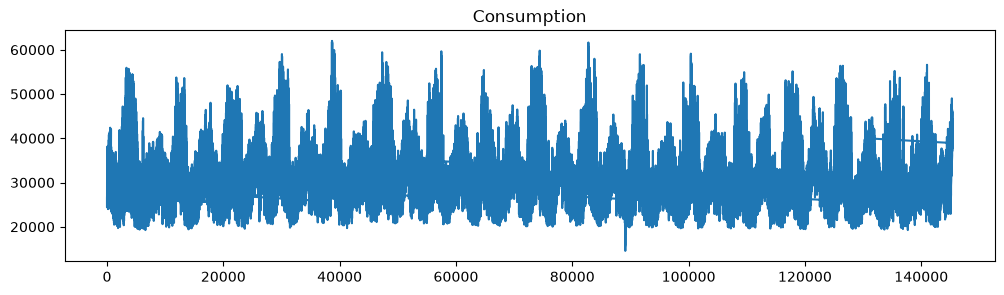

In [5]:
print("Zero or negative values:", (df[target] <= 0).sum())

q1, q3 = df[target].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 3 * iqr, q3 + 3 * iqr
outliers = df[(df[target] < low) | (df[target] > high)]
print("Extreme outliers:", len(outliers))

df[target].plot(figsize=(12, 3), title="Consumption")

In [6]:
df.loc[df[target] <= 0, target] = pd.NA

df = df.set_index("Datetime").reindex(full_range)
df.index.name = "Datetime"

df[target] = df[target].astype(float).interpolate(method="time", limit=6)
df = df.dropna(subset=[target])

df = df.sort_index().reset_index()
print("Remaining missing:", df[target].isna().sum(), "| rows:", len(df))

Remaining missing: 0 | rows: 145392


In [7]:
df.to_csv("../data/processed/electric_clean.csv", index=False)